<a href="https://colab.research.google.com/github/LeodosR/Customer-segmentation-kmeans/blob/main/Customer_segmentaiton_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Overview**

# Customer Segmentation: E-commerce Orders

**Goal:** Group customers by purchasing behaviour so that marketing can be targeted at each group rather than at everyone.

**Data:** About 950,000 order lines from an international retailer, covering customers in 47 countries across five continents between 2012 and 2016. Each row holds details about the order (dates, quantity, revenue, cost, discount, profit) and the customer (location, loyalty group, birthdate). Source: SAS, 2024. CUSTOMERS_CLEAN [Data set]. SAS. Last revised on 15 December 2021. [Accessed 20 February 2024].

**Approach:**

Cleaned the data and engineered customer-level features: recency, frequency, customer lifetime value, average unit cost and age.

Chose the optimal number of clusters (4) using the Elbow Method, Silhouette Scores and hierarchical clustering.

Segmented customers with K-Means, and used PCA and t-SNE to visualise and interpret the groups.

**Outcome:** Identified 4 key customer segments, including high spenders, older and younger customers and a cluster of new clientel. As t-SNE visualised our resulting cluster better than PCA (which we can attribute to non-linearity), with a perplexity level of 50, it demonstrated clearly separated our 'champs' and 'fresh catch' clusters, while out younger and older categories show marginal ovelapping.

# > Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

data = pd.read_csv('https://github.com/FourthRevGitHub/CAM_DS_Public-Data-Sets/raw/main/Course%201/Week%206/CUSTOMERS_CLEAN.zip')

In [2]:
data.head(20)

,Quantity,City,Continent,Postal_Code,State_Province,Order_Date,Delivery_Date,Total Revenue,Unit Cost,Discount,OrderTypeLabel,CustomerCountryLabel,Customer_BirthDate,Customer_Group,Customer_Type,Order ID,Profit,Days to Delivery,Loyalty Num,Customer ID
0,3,Leinster,Oceania,6437,Western Australia,01JAN2012,07JAN2012,$28.50,$9.10,.,Internet Sale,Australia,08MAY1978,Internet/Catalog Customers,Internet/Catalog Customers,1230000033,$1.20,6,99,8818
1,2,Berowra,Oceania,2081,New South Wales,01JAN2012,04JAN2012,$113.40,$56.90,.,Internet Sale,Australia,13DEC1978,Orion Club Gold members,Orion Club Gold members high activity,1230000204,($0.40),3,99,47793
2,2,Berowra,Oceania,2081,New South Wales,01JAN2012,04JAN2012,$41.00,$18.50,.,Internet Sale,Australia,13DEC1978,Orion Club Gold members,Orion Club Gold members high activity,1230000204,$4.00,3,99,47793
3,1,Northbridge,Oceania,2063,New South Wales,01JAN2012,03JAN2012,$35.20,$29.60,.,Internet Sale,Australia,22JUN1997,Orion Club Gold members,Orion Club Gold members high activity,1230000268,$5.60,2,0,71727
4,1,Montréal,North America,NaN,Quebec,01JAN2012,04JAN2012,$24.70,$23.60,.,Internet Sale,Canada,28JAN1978,Orion Club Gold members,Orion Club Gold members medium activity,1230000487,$1.10,3,99,74503
5,1,Herrenschwanden,Europe,3037,NaN,01JAN2012,07JAN2012,$136.10,$132.20,.,Internet Sale,Switzerland,06MAY1963,Orion Club Gold members,Orion Club Gold members medium activity,1230000494,$3.90,6,99,8610
6,2,Monheim-Baumberg,Europe,40789,Berlin,01JAN2012,05JAN2012,$358.60,$164.00,.,Internet Sale,Germany,22JAN1997,Internet/Catalog Customers,Internet/Catalog Customers,1230000689,$30.60,4,99,19278
7,1,Frankfurt am Main,Europe,60295,Hessen,01JAN2012,04JAN2012,$1.70,$1.60,.,Internet Sale,Germany,23JAN1995,Orion Club Gold members,Orion Club Gold members high activity,1230000871,$0.10,3,0,28861
8,1,Frankfurt am Main,Europe,60325,Hessen,01JAN2012,04JAN2012,$155.80,$129.90,.,Internet Sale,Germany,22DEC1983,Internet/Catalog Customers,Internet/Catalog Customers,1230001178,$25.90,3,0,57972
9,1,Frankfurt am Main,Europe,60325,Hessen,01JAN2012,04JAN2012,$39.00,$30.00,.,Internet Sale,Germany,22DEC1983,Internet/Catalog Customers,Internet/Catalog Customers,1230001178,$9.00,3,0,57972


# Data Pre-processing/Cleaning

In [3]:
for col in data:
  unique_val = data[col].nunique()
  print(f"Unique values for '{col}': {unique_val}")

Unique values for 'Quantity': 10
Unique values for 'City': 10505
Unique values for 'Continent': 5
Unique values for 'Postal_Code': 19339
Unique values for 'State_Province': 271
Unique values for 'Order_Date': 1825
Unique values for 'Delivery_Date': 1840
Unique values for 'Total Revenue': 6894
Unique values for 'Unit Cost': 1883
Unique values for 'Discount': 5
Unique values for 'OrderTypeLabel': 3
Unique values for 'CustomerCountryLabel': 47
Unique values for 'Customer_BirthDate': 4368
Unique values for 'Customer_Group': 3
Unique values for 'Customer_Type': 7
Unique values for 'Order ID': 747953
Unique values for 'Profit': 3520
Unique values for 'Days to Delivery': 32
Unique values for 'Loyalty Num': 2
Unique values for 'Customer ID': 68300


In [4]:
data.isnull().sum()

,0
Quantity,0
City,135
Continent,0
Postal_Code,3716
State_Province,117192
Order_Date,0
Delivery_Date,0
Total Revenue,0
Unit Cost,0
Discount,0


So we have quite a complete dataset, with only a minor amount of missing values in city, more in postal code. However, state_province in missing a substantial amount of values.

Based on the clustering and feature creation we are intending to carry out, we can determine that the most important features for us do not have null values, and as such we will leave them untouched as they will be excluded later on in our process.

In [5]:
data.dtypes

,0
Quantity,int64
City,object
Continent,object
Postal_Code,object
State_Province,object
Order_Date,object
Delivery_Date,object
Total Revenue,object
Unit Cost,object
Discount,object


Given the high amount of object features, we shall rework those with numerical values in order to allow greater data analysis

Visually, the brackets are likely to represent negative values, and as such need to be properly cleaned

In [6]:
data.duplicated().sum()

np.int64(21)

We also appear to have 21 identical rows

In [7]:
data[data.duplicated(keep=False)]

,Quantity,City,Continent,Postal_Code,State_Province,Order_Date,Delivery_Date,Total Revenue,Unit Cost,Discount,OrderTypeLabel,CustomerCountryLabel,Customer_BirthDate,Customer_Group,Customer_Type,Order ID,Profit,Days to Delivery,Loyalty Num,Customer ID
25808,1,Köln,Europe,51105,Nordrhein-Westfalen,08MAR2012,08MAR2012,$59.70,$59.90,.,Retail Sale,Germany,15MAR1958,Orion Club members,Orion Club members medium activity,1230368036,($0.20),0,99,29993
25809,1,Köln,Europe,51105,Nordrhein-Westfalen,08MAR2012,08MAR2012,$59.70,$59.90,.,Retail Sale,Germany,15MAR1958,Orion Club members,Orion Club members medium activity,1230368036,($0.20),0,99,29993
59722,2,Roma,Europe,00167,Lazio,24MAY2012,24MAY2012,$26.40,$11.90,.,Retail Sale,Italy,18SEP1993,Orion Club Gold members,Orion Club Gold members high activity,1230792924,$2.60,0,99,91394
59723,2,Roma,Europe,00167,Lazio,24MAY2012,24MAY2012,$26.40,$11.90,.,Retail Sale,Italy,18SEP1993,Orion Club Gold members,Orion Club Gold members high activity,1230792924,$2.60,0,99,91394
60474,1,Madrid,Europe,28042,"Madrid, Comunidad de",26MAY2012,29MAY2012,$55.10,$55.30,.,Catalog Sale,Spain,08MAR1968,Orion Club Gold members,Orion Club Gold members high activity,1230801908,($0.20),3,0,74401
60475,1,Madrid,Europe,28042,"Madrid, Comunidad de",26MAY2012,29MAY2012,$55.10,$55.30,.,Catalog Sale,Spain,08MAR1968,Orion Club Gold members,Orion Club Gold members high activity,1230801908,($0.20),3,0,74401
71115,2,Brooklyn,North America,11231,New York,17JUN2012,17JUN2012,$53.98,$20.46,.,Retail Sale,United States,17JUL1997,Orion Club members,Orion Club members low activity,1230923543,$13.06,0,99,6901
71116,2,Brooklyn,North America,11231,New York,17JUN2012,17JUN2012,$53.98,$20.46,.,Retail Sale,United States,17JUL1997,Orion Club members,Orion Club members low activity,1230923543,$13.06,0,99,6901
85385,2,Floral Park,North America,11001,New York,17JUL2012,17JUL2012,$85.60,$43.00,.,Retail Sale,United States,09AUG1958,Orion Club members,Orion Club members low activity,1231089144,($0.40),0,99,21840
85386,2,Floral Park,North America,11001,New York,17JUL2012,17JUL2012,$85.60,$43.00,.,Retail Sale,United States,09AUG1958,Orion Club members,Orion Club members low activity,1231089144,($0.40),0,99,21840


In [8]:
data = data.drop_duplicates()

data.duplicated().sum()

np.int64(0)

In [9]:
price_cols = ['Total Revenue', 'Unit Cost', 'Profit']

for col in price_cols:
    s = data[col].astype(str).str.strip()

    has_brackets = s.str.contains(r'\(.*\)', regex=True, na=False)

    s_clean = s.str.replace(r'[\$,\(\)]', '', regex=True).str.strip()

    s_clean = np.where(has_brackets, '-' + s_clean, s_clean)

    data[col] = pd.to_numeric(s_clean, errors='coerce')

In [10]:
invalid_rev = data[data['Total Revenue'] < 0]
invalid_cost = data[data['Unit Cost'] < 0]

print(len(invalid_rev))
print(len(invalid_cost))

0
0


So now we have made three important features numerical, and can validate that the profit section accounts for negative values, whilst there were no issues with this for total revenue or the unit cost

In [11]:
print(data['Discount'].unique())

['   .' '50%' '40%' '30%' '60%']


In [12]:
re_work = {'   .': 0, '50%': 0.5, '40%': 0.4, '30%': 0.3, '60%': 0.6}
data['Discount'] = data['Discount'].map(re_work)
data.head()


,Quantity,City,Continent,Postal_Code,State_Province,Order_Date,Delivery_Date,Total Revenue,Unit Cost,Discount,OrderTypeLabel,CustomerCountryLabel,Customer_BirthDate,Customer_Group,Customer_Type,Order ID,Profit,Days to Delivery,Loyalty Num,Customer ID
0,3,Leinster,Oceania,6437,Western Australia,01JAN2012,07JAN2012,28.5,9.1,0.0,Internet Sale,Australia,08MAY1978,Internet/Catalog Customers,Internet/Catalog Customers,1230000033,1.2,6,99,8818
1,2,Berowra,Oceania,2081,New South Wales,01JAN2012,04JAN2012,113.4,56.9,0.0,Internet Sale,Australia,13DEC1978,Orion Club Gold members,Orion Club Gold members high activity,1230000204,-0.4,3,99,47793
2,2,Berowra,Oceania,2081,New South Wales,01JAN2012,04JAN2012,41.0,18.5,0.0,Internet Sale,Australia,13DEC1978,Orion Club Gold members,Orion Club Gold members high activity,1230000204,4.0,3,99,47793
3,1,Northbridge,Oceania,2063,New South Wales,01JAN2012,03JAN2012,35.2,29.6,0.0,Internet Sale,Australia,22JUN1997,Orion Club Gold members,Orion Club Gold members high activity,1230000268,5.6,2,0,71727
4,1,Montréal,North America,NaN,Quebec,01JAN2012,04JAN2012,24.7,23.6,0.0,Internet Sale,Canada,28JAN1978,Orion Club Gold members,Orion Club Gold members medium activity,1230000487,1.1,3,99,74503


Discount has now been made into a float to allow easier usage

In [13]:
date_cols = ['Order_Date', 'Delivery_Date', 'Customer_BirthDate']
for col in date_cols:
  data[col] = pd.to_datetime(data[col], format='%d%b%Y')
data.head()

,Quantity,City,Continent,Postal_Code,State_Province,Order_Date,Delivery_Date,Total Revenue,Unit Cost,Discount,OrderTypeLabel,CustomerCountryLabel,Customer_BirthDate,Customer_Group,Customer_Type,Order ID,Profit,Days to Delivery,Loyalty Num,Customer ID
0,3,Leinster,Oceania,6437,Western Australia,2012-01-01,2012-01-07,28.5,9.1,0.0,Internet Sale,Australia,1978-05-08,Internet/Catalog Customers,Internet/Catalog Customers,1230000033,1.2,6,99,8818
1,2,Berowra,Oceania,2081,New South Wales,2012-01-01,2012-01-04,113.4,56.9,0.0,Internet Sale,Australia,1978-12-13,Orion Club Gold members,Orion Club Gold members high activity,1230000204,-0.4,3,99,47793
2,2,Berowra,Oceania,2081,New South Wales,2012-01-01,2012-01-04,41.0,18.5,0.0,Internet Sale,Australia,1978-12-13,Orion Club Gold members,Orion Club Gold members high activity,1230000204,4.0,3,99,47793
3,1,Northbridge,Oceania,2063,New South Wales,2012-01-01,2012-01-03,35.2,29.6,0.0,Internet Sale,Australia,1997-06-22,Orion Club Gold members,Orion Club Gold members high activity,1230000268,5.6,2,0,71727
4,1,Montréal,North America,NaN,Quebec,2012-01-01,2012-01-04,24.7,23.6,0.0,Internet Sale,Canada,1978-01-28,Orion Club Gold members,Orion Club Gold members medium activity,1230000487,1.1,3,99,74503


We have engineered some of the object rows into numeric columns, which serve us purpoose appropriately, we have dropped the duplicate rows, and can now begin feature engineering with the knowledge that the data we have should be sufficient.

# Feature Engineering

The first thing to note before feature enginerring is that not all the columns in our dataset are necessary. Given the criteria of the 5 features we must engineer, it is clear that information such as location is not an essential part of our features, which means those null values we observed earlier are not an issue.

In [14]:
fe_data = data.copy()

In [15]:
fe_data['Frequency'] = fe_data.groupby('Customer ID')['Order ID'].transform('count')
fe_data['Frequency'].head(10)

,Frequency
0,31
1,20
2,20
3,20
4,6
5,3
6,12
7,31
8,14
9,14


Will quickly validate the frequency of the one example row (the first)

In [16]:
first_customer = data['Customer ID'].iloc[0]

actual_count = (data['Customer ID'] == first_customer).sum()

print(f"Customer ID {first_customer} appears {actual_count} times.")

Customer ID 8818 appears 31 times.


In [17]:
print(fe_data[fe_data['Customer ID'] == first_customer][['Customer ID', 'Order ID', 'Frequency']])

        Customer ID    Order ID  Frequency
0              8818  1230000033         31
474            8818  1230011283         31
475            8818  1230011283         31
22618          8818  1230320300         31
22619          8818  1230320300         31
49314          8818  1230670254         31
49572          8818  1230673996         31
65200          8818  1230855066         31
65201          8818  1230855066         31
77725          8818  1231002260         31
100885         8818  1231272306         31
105886         8818  1231332085         31
139544         8818  1231821879         31
150507         8818  1231946959         31
323862         8818  1234274610         31
332871         8818  1234382848         31
391224         8818  1235438860         31
464598         8818  1236581264         31
505345         8818  1237331082         31
505346         8818  1237331082         31
512390         8818  1237460330         31
536773         8818  1237872788         31
577233     

In [18]:
fe_data['Recency'] = (pd.to_datetime('today') - pd.to_datetime(fe_data['Delivery_Date'])).dt.days

In [19]:
fe_data['Recency'].head(20)

,Recency
0,5410
1,5413
2,5413
3,5414
4,5413
5,5410
6,5412
7,5413
8,5413
9,5413


In [20]:
fe_data['Average_Unit_Cost'] = fe_data.groupby('Customer ID')['Unit Cost'].transform('mean')

fe_data['Average_Unit_Cost'].head(20)

,Average_Unit_Cost
0,60.206452
1,66.280000
2,66.280000
3,74.775000
4,74.300000
5,183.866667
6,118.333333
7,72.990323
8,71.142857
9,71.142857


In [21]:
fe_data['Customer_Age'] = (pd.to_datetime('today') - data['Customer_BirthDate']).dt.days // 365
fe_data['Customer_Age'].head(20)

,Customer_Age
0,48
1,47
2,47
3,29
4,48
5,63
6,29
7,31
8,42
9,42


In [22]:
customer_df = fe_data.groupby('Customer ID').agg(
    Frequency=('Frequency', 'first'),
    Recency=('Recency', 'first'),
    Average_Unit_Cost=('Average_Unit_Cost', 'first'),
    Customer_Age=('Customer_Age', 'first'),
    CLV=('Total Revenue', 'sum')
).reset_index()

Because of the nature of our features, I have left aggregation to the last step - this way, we can apply it effectively to CLV.

In [23]:
customer_df.head()

,Customer ID,Frequency,Recency,Average_Unit_Cost,Customer_Age,CLV
0,1,35,4801,89.622857,72,4322.70
1,3,20,5367,90.505000,43,2821.00
2,4,9,4989,37.195556,43,782.67
3,5,19,5398,107.947368,38,2810.98
4,6,15,5003,52.526667,67,1604.58


In [24]:
customer_df.shape

(68300, 6)

So now we have completed the feature creation and aggregation of the data. We have the new dataframe from which we can explore and move on to clustering.

# Exploratory Data Analysis (EDA) of New Features

In [25]:
feat_cols = ['Frequency',
    'Recency',
    'Average_Unit_Cost',
    'Customer_Age',
    'CLV',
]

In [26]:
customer_df[feat_cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68300 entries, 0 to 68299
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Frequency          68300 non-null  int64  
 1   Recency            68300 non-null  int64  
 2   Average_Unit_Cost  68300 non-null  float64
 3   Customer_Age       68300 non-null  int64  
 4   CLV                68300 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 2.6 MB


In [27]:
customer_df[feat_cols].describe()

,Frequency,Recency,Average_Unit_Cost,Customer_Age,CLV
count,68300.000000,68300.000000,68300.000000,68300.000000,68300.000000
mean,13.933353,5020.839707,78.895675,52.971962,1950.148420
std,11.328807,403.056033,38.005259,17.488892,1719.916365
min,1.000000,3585.000000,0.500000,28.000000,0.630000
25%,6.000000,4861.000000,57.579792,38.000000,696.000000
50%,11.000000,5162.000000,73.450000,53.000000,1497.400000
75%,19.000000,5335.000000,92.515260,68.000000,2709.845000
max,121.000000,5415.000000,1463.500000,83.000000,18860.960000


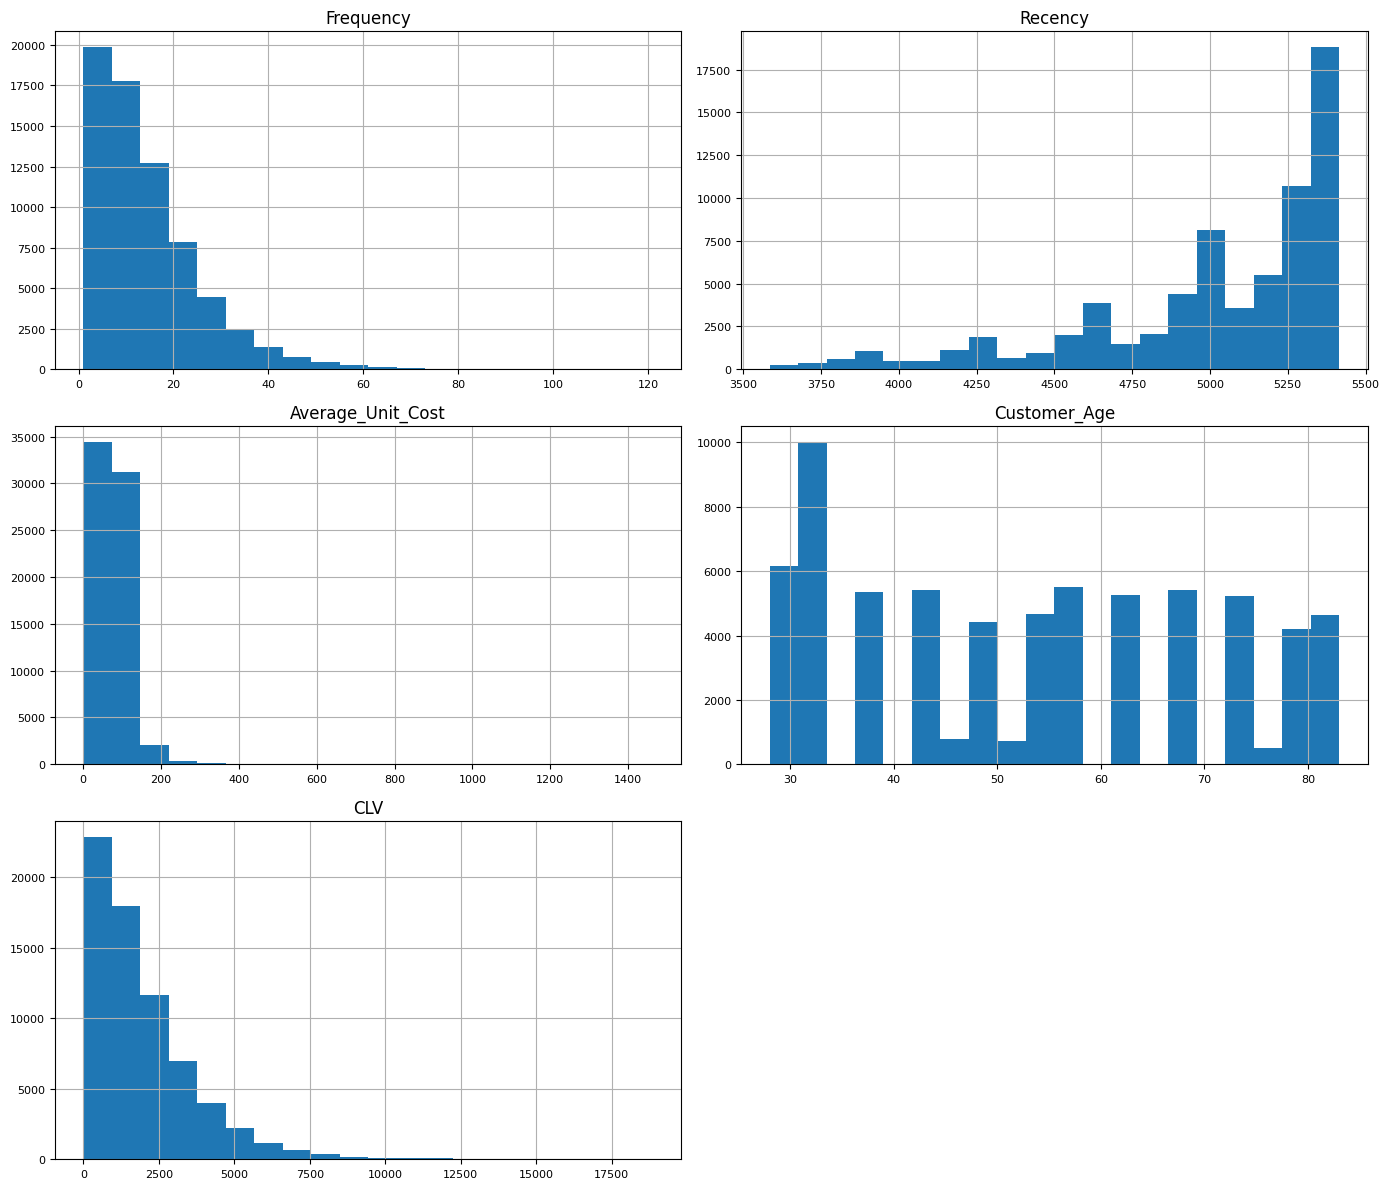

In [28]:
customer_df[feat_cols].hist(figsize=(14, 12), bins=20, xlabelsize=8, ylabelsize=8)
plt.tight_layout()
plt.show()

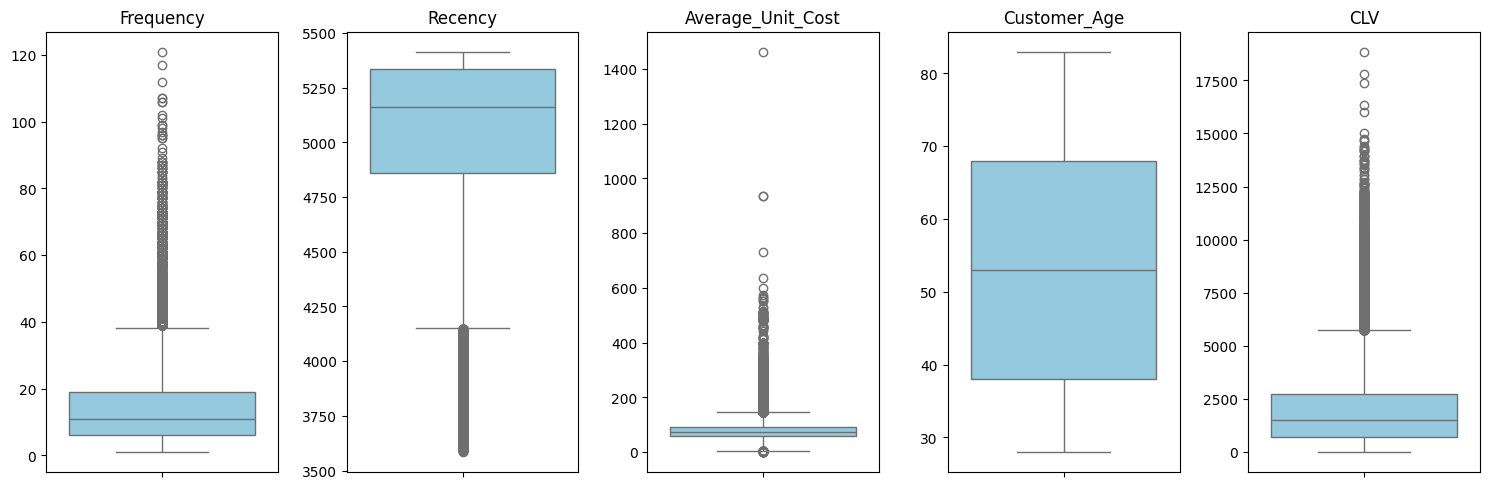

In [29]:
fig, axes = plt.subplots(1, len(feat_cols), figsize=(15, 5))

for i, col in enumerate(feat_cols):
  sns.boxplot(y=customer_df[col], ax=axes[i], color='skyblue')
  axes[i].set_title(col)
  axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

The data of these 5 features is not normally distributed, as shown by the histogram plots we have. In terms of outliers, we do have a high amount of outliers arising from frequency, recency, average unit cost and customer lifetime value. Given the nature of customer segmentation analysis, I will keep the anomalies as they are likely to give valuable insight into our customer base, given that anomalies are prevalent in features where this information is useful, such as frequency, and CLV.

We are going to standardise the data, particularly because k-means is sensitive to unscaled data.

In [30]:
scaler = StandardScaler()
customer_df[feat_cols] = scaler.fit_transform(customer_df[feat_cols])


In [31]:
customer_df[feat_cols].head()

,Frequency,Recency,Average_Unit_Cost,Customer_Age,CLV
0,1.859578,-0.545436,0.282257,1.088015,1.379468
1,0.535510,0.858845,0.305469,-0.570193,0.506337
2,-0.435473,-0.078996,-1.097228,-0.570193,-0.678804
3,0.447239,0.935758,0.764418,-0.856090,0.500511
4,0.094154,-0.044261,-0.693830,0.802117,-0.200923


# Clustering with ML models: K-means

So now our features are scaled, we will begin to try and work out the optimal $k$ number (of clusters). We will begin with the elbow method, then silhouette score, and finally hierarchical clustering to optomise choosing the $k$-number.

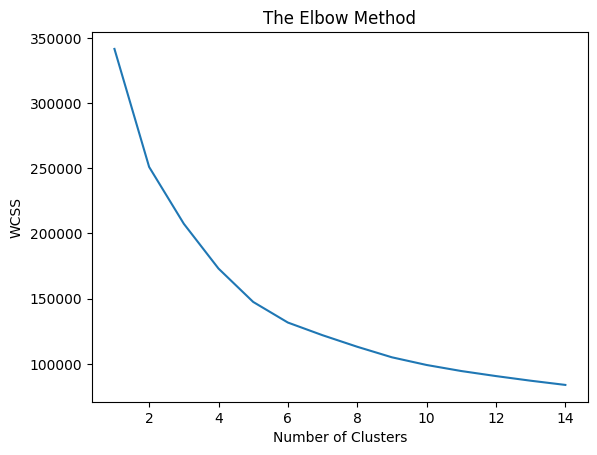

In [32]:
wcss=[]
for i in range(1,15):
    kmeans=KMeans(n_clusters=i, init='k-means++',random_state=0, n_init = 10)
    kmeans.fit(customer_df[feat_cols])
    wcss.append(kmeans.inertia_)

plt.plot(range(1,15),wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

Firstly we have applied the elbow method. This is a useful tool to start the process of picking the optimal $k$ number. Visually, $k$ 4-5 allow shows a reasonable transition in the line, with 4 a key part of where the curve begins to flatten, while 6 seems to demonstrate a significant change of direction. However we will utilise other methods to determine the correct $k$ number.

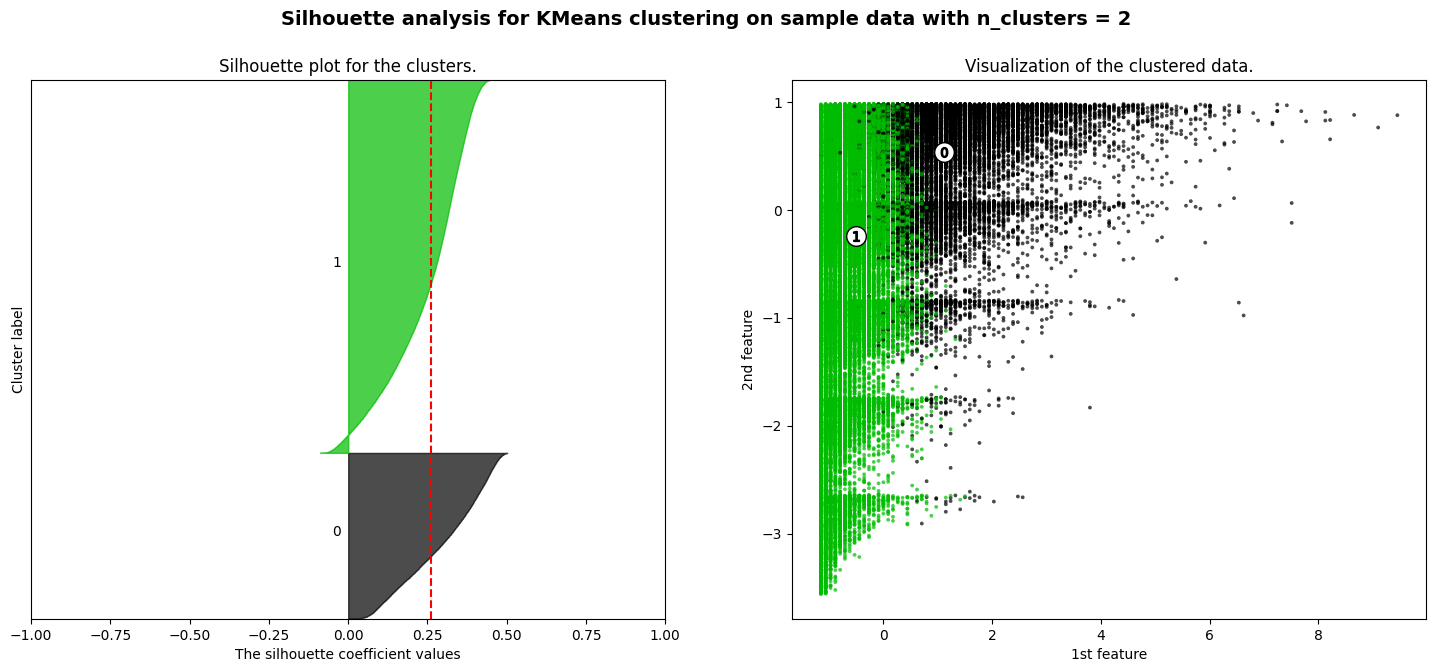

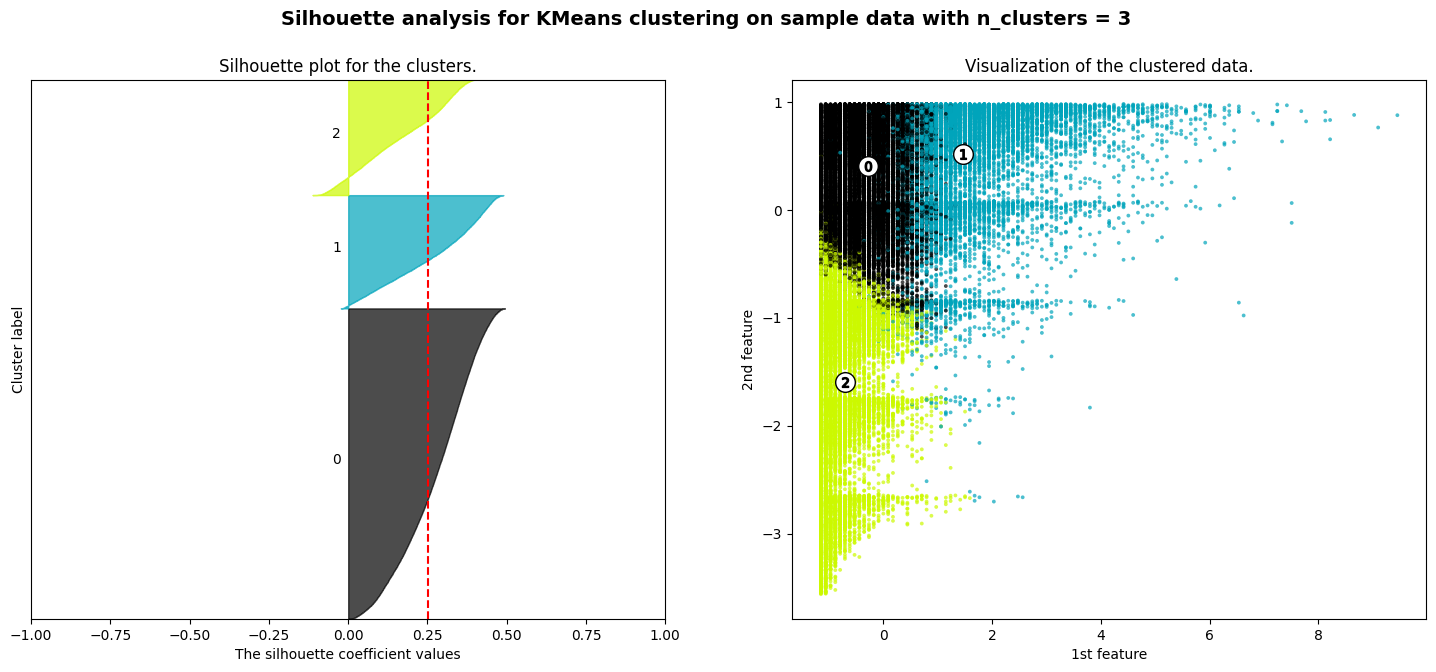

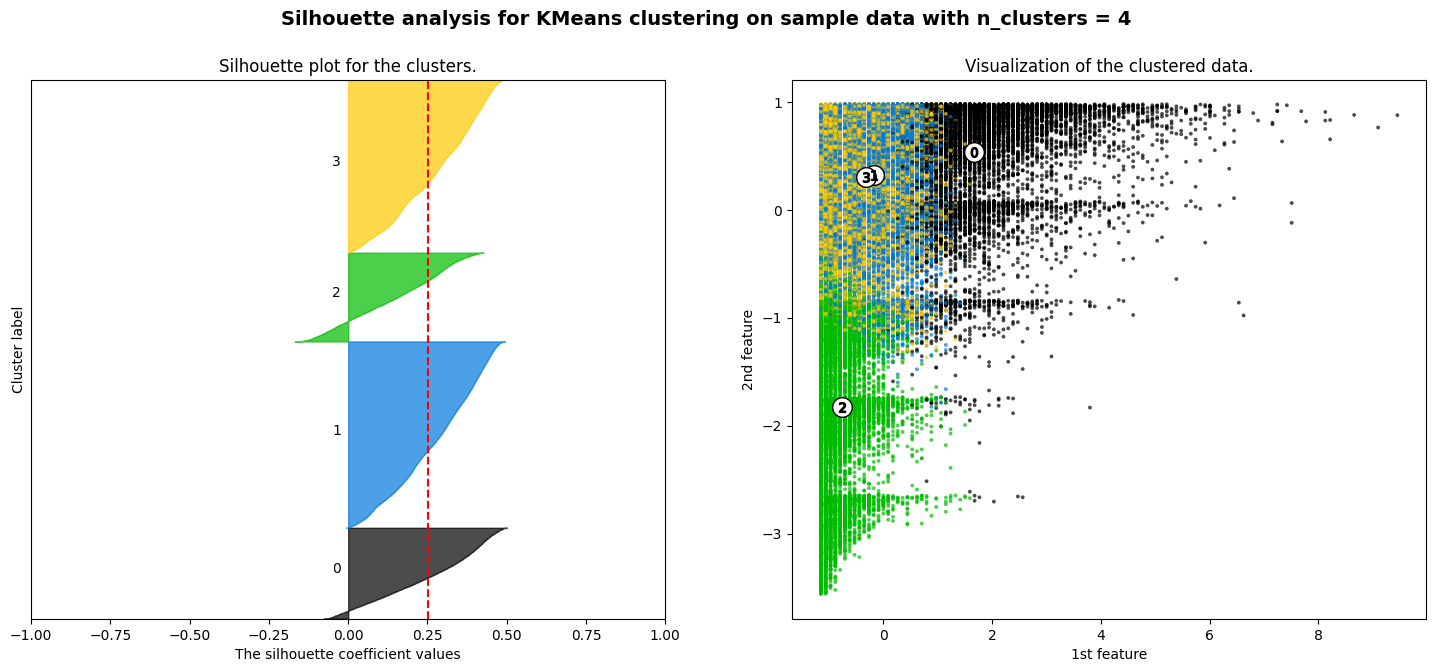

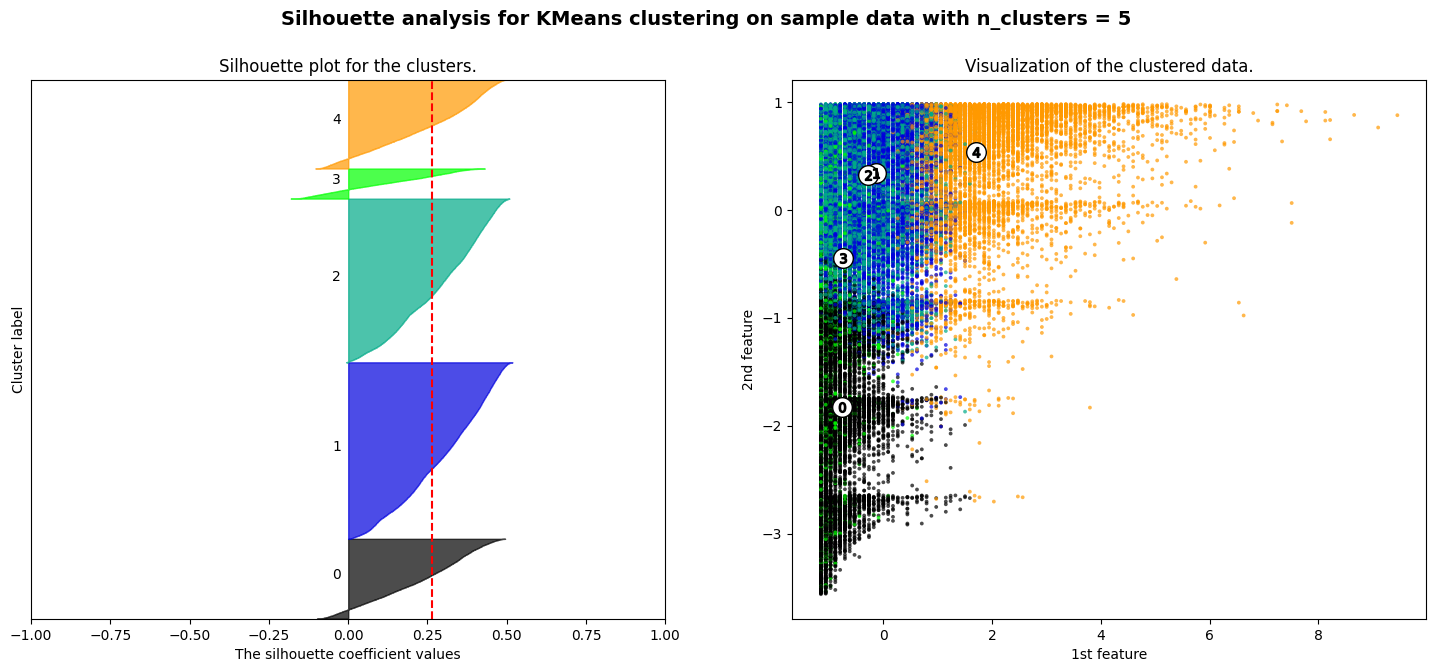

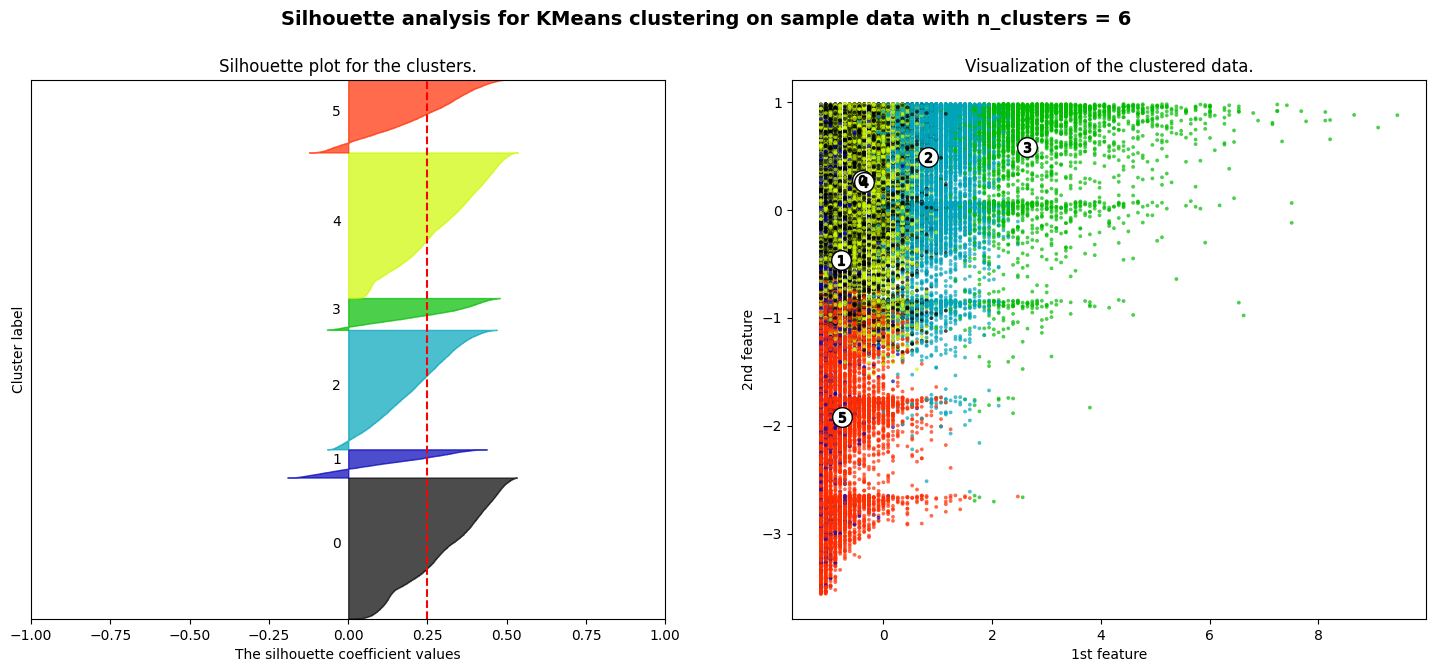

In [33]:
import matplotlib.cm as cm

range_n_clusters = [2, 3, 4, 5, 6]

for n_clusters in range_n_clusters:
  fig, (ax1, ax2) = plt.subplots(1, 2)
  fig.set_size_inches(18, 7)

  ax1.set_xlim([-1, 1])
  ax1.set_ylim([0, len(customer_df) + (n_clusters + 1) * 10])

  clusterer = KMeans(n_clusters=n_clusters, random_state=10, n_init=10)
  cluster_labels = clusterer.fit_predict(customer_df[feat_cols])

  silhouette_avg = silhouette_score(customer_df[feat_cols], cluster_labels)

  sample_silhouette_values = silhouette_samples(
      customer_df[feat_cols], cluster_labels
  )

  y_lower = 10
  for i in range(n_clusters):
    ith_cluster_silhouette_values = sample_silhouette_values[
        cluster_labels == i
    ]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / n_clusters)
    ax1.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_silhouette_values,
        facecolor=color,
        edgecolor=color,
        alpha=0.7,
    )

    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10

  ax1.set_title('Silhouette plot for the clusters.')
  ax1.set_xlabel('The silhouette coefficient values')
  ax1.set_ylabel('Cluster label')

  ax1.axvline(x=silhouette_avg, color='red', linestyle='--')

  ax1.set_yticks([])
  ax1.set_xticks([-1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1])

  colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
  X_array = customer_df[feat_cols].values
  ax2.scatter(
      X_array[:, 0],
      X_array[:, 1],
      marker='.',
      s=30,
      lw=0,
      alpha=0.7,
      c=colors,
      edgecolor='k',
  )

  centers = clusterer.cluster_centers_
  X_array = customer_df[feat_cols].values
  ax2.scatter(
      centers[:, 0],
      centers[:, 1],
      marker='o',
      c='white',
      alpha=1,
      s=200,
      edgecolor='k',
  )

  for i, c in enumerate(centers):
    ax2.scatter(
        c[0], c[1], marker='$%d$' % i, alpha=1, s=50, edgecolor='k'
    )

  ax2.set_title('Visualization of the clustered data.')
  ax2.set_xlabel('1st feature')
  ax2.set_ylabel('2nd feature')

  plt.suptitle(
      'Silhouette analysis for KMeans clustering on sample data with n_clusters'
      ' = %d' % n_clusters,
      fontsize=14,
      fontweight='bold',
  )
  plt.show()

Silhouette Score Summary
For n_clusters = 2, Silhouette Score: 0.2627
For n_clusters = 3, Silhouette Score: 0.2508
For n_clusters = 4, Silhouette Score: 0.2507
For n_clusters = 5, Silhouette Score: 0.2639
For n_clusters = 6, Silhouette Score: 0.2495


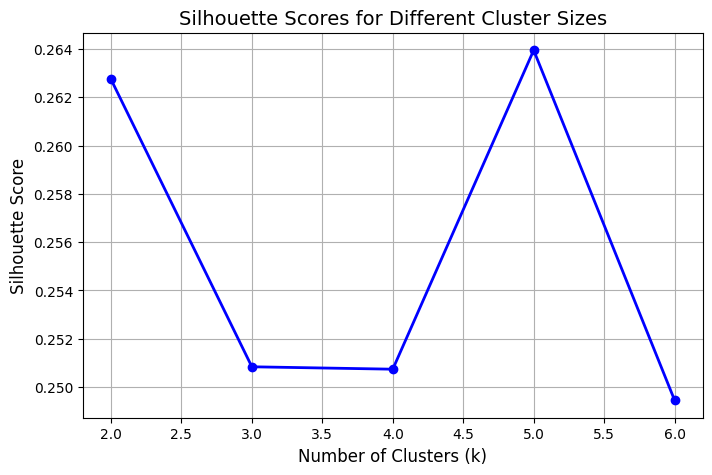

In [34]:
k_range = range(2, 7)
silhouette_scores = []

print("Silhouette Score Summary")
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(customer_df[feat_cols])

    score = silhouette_score(customer_df[feat_cols], cluster_labels)
    silhouette_scores.append(score)
    print(f"For n_clusters = {k}, Silhouette Score: {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, marker='o', linestyle='-', color='b', linewidth=2)
plt.title('Silhouette Scores for Different Cluster Sizes', fontsize=14)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.grid(True)
plt.show()

Combining the visual representations and the summary table, the silhouette score peaks at 5, representing a mraginally higher score than $k$ = 2. However, the range of silhouette scores is relatively low, with only a 0.015 difference between the highest and lowest ranking $k$ numbers. Therefore, considering the nature of this analysis, we are still looking between the 4-6 range to create effective customer clusters.

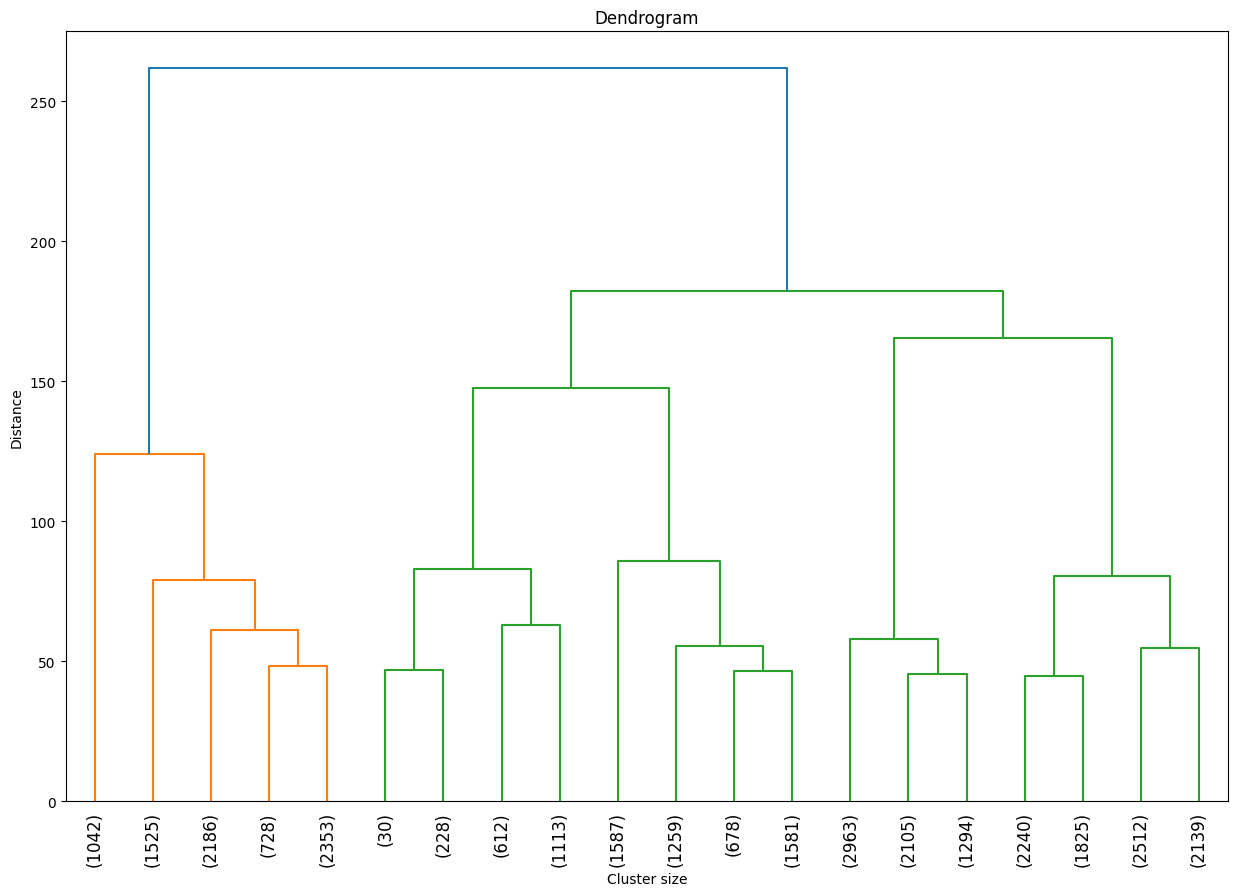

In [35]:
hc_data = customer_df[feat_cols].sample(n=30000, random_state=42).reset_index(drop=True)

def hierarchical_clustering(data, method='ward'):
    dists = pdist(data, metric='euclidean')
    linkage_matrix = linkage(dists, method=method)
    return linkage_matrix

linkage_matrix = hierarchical_clustering(hc_data)

plt.figure(figsize=(15, 10))
dendrogram(linkage_matrix,
           truncate_mode='lastp',
           p=20,
           leaf_rotation=90,
           leaf_font_size=12
           )
plt.title('Dendrogram')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()

And our final technique, hierarchical clustering, suggests that if the most suitable line placement would be around the 175-200 distance mark. This suggests $k=3$ given the distance between the clusters. Just below, around the 140-150 mark, $k=4$ is also a viable option.

So in summary, the silhouette score peaked at $k = 5$, the elbow method suggested a transition around $k = 3-6$, and the hierarchical dendrogram points to $k = 3$. Considering particularly our previous interpretation of the elbow method, where 4 did represent a bend in the elbow, and the small statistical difference in the silhouette scores, 4 seems like a strong choice for optimal $k$. While 3 looks to be a strong choice within the methods, 4 gives more potential to identify the clusters with defining attributes. It is a compromise between the 3 methods. Balancing statistical support with business interpretability for actionable results, we will use $k = 4$ because from there we can aim to create distinct grouping.

As such, we shall fit our k-means clustering using $k$ = 4.

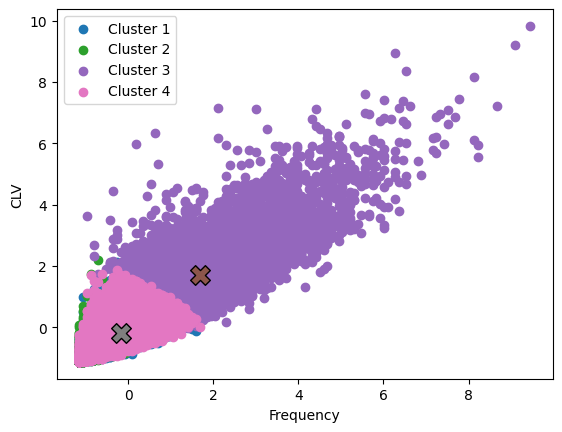

Centroids: [[-0.31350918  0.30396646 -0.11267799  0.96019944 -0.3418549 ]
 [-0.76126595 -1.82620778  0.08326912  0.16663293 -0.69497503]
 [ 1.68219509  0.53701071  0.11727836 -0.23585813  1.70923133]
 [-0.16056718  0.32774345  0.00822498 -0.85741139 -0.17891128]]


In [36]:
kmeans = KMeans(n_clusters=4, random_state=42,  n_init=10)
customer_df['cluster'] = kmeans.fit_predict(customer_df[feat_cols])

centroids = kmeans.cluster_centers_

i = feat_cols.index('Frequency')
j = feat_cols.index('CLV')

for cluster_idx in range(4):
    cluster_data = customer_df[customer_df['cluster'] == cluster_idx]
    plt.scatter(cluster_data['Frequency'],
                cluster_data['CLV'],
                label=f'Cluster {cluster_idx + 1}')
    plt.scatter(
        centroids[cluster_idx][i],
        centroids[cluster_idx][j],
        s=200,
        marker='X',
        edgecolors='black'
    )

plt.xlabel('Frequency')
plt.ylabel('CLV')
plt.legend()
plt.show()

print("Centroids:", centroids)

# Visualising the Clusters

Within the k-means operation, we have appended the cluster number to the customer_df dataframe.

In [37]:
print(customer_df.head(10))

   Customer ID  Frequency   Recency  Average_Unit_Cost  Customer_Age  \
0            1   1.859578 -0.545436           0.282257      1.088015   
1            3   0.535510  0.858845           0.305469     -0.570193   
2            4  -0.435473 -0.078996          -1.097228     -0.570193   
3            5   0.447239  0.935758           0.764418     -0.856090   
4            6   0.094154 -0.044261          -0.693830      0.802117   
5            7   1.506493  0.665323          -0.877530     -0.856090   
6            9   0.712053  0.722387           0.621444     -0.570193   
7           10   1.594765 -1.227728           0.055288     -1.141988   
8           11  -0.435473  0.940720          -1.063782     -0.570193   
9           12   0.182425  0.640512          -0.686145     -0.284295   

        CLV  cluster  
0  1.379468        2  
1  0.506337        3  
2 -0.678804        3  
3  0.500511        3  
4 -0.200923        0  
5  0.239869        2  
6  1.653669        2  
7  1.547262        2  


In [38]:
print(customer_df['cluster'].value_counts())

cluster
3    23627
0    21947
2    11477
1    11249
Name: count, dtype: int64


To display our new clusters against the original values for the features, before the scaling, we will have to revert them back. It would be better in future operations to hold an original copy, but for convenience purposes we will reverse the scaling.

In [39]:
customer_df_unscaled = customer_df.copy()

customer_df_unscaled[feat_cols] = scaler.inverse_transform(customer_df[feat_cols])

In [40]:
customer_df_unscaled['cluster'] = customer_df_unscaled['cluster'] + 1

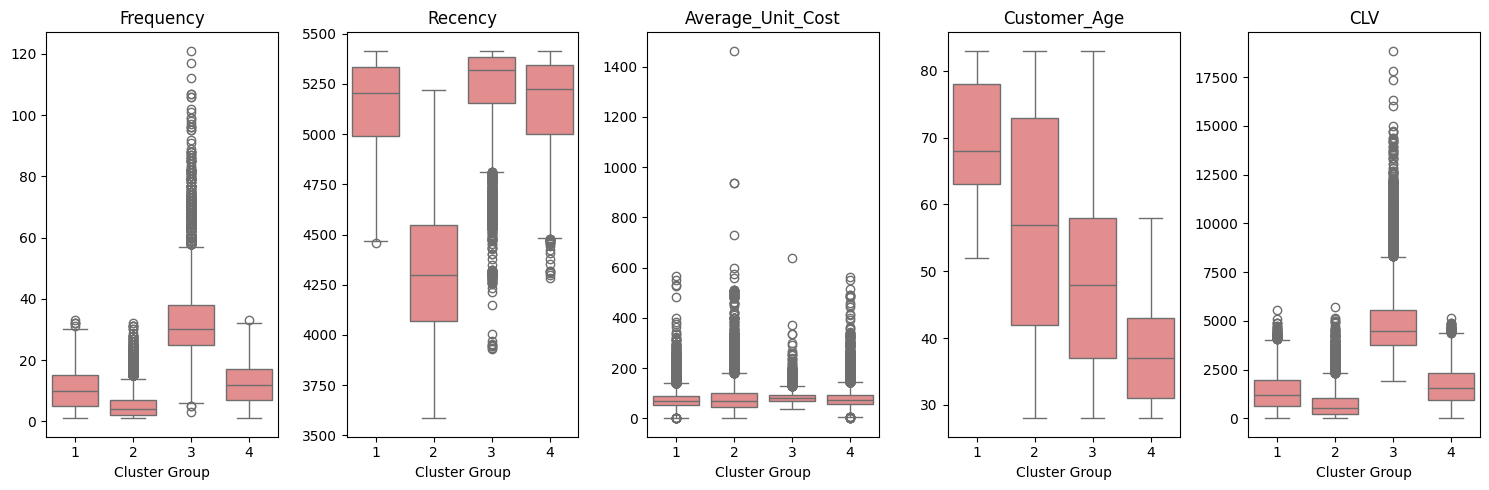

In [41]:
fig, axes = plt.subplots(1, len(feat_cols), figsize=(15, 5))

for i, col in enumerate(feat_cols):
  sns.boxplot(
      data = customer_df_unscaled,
      x=customer_df_unscaled['cluster'],
      y=customer_df_unscaled[col], ax=axes[i], color='lightcoral')
  axes[i].set_title(col)
  axes[i].set_xlabel('Cluster Group')
  axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

With these clusters, we can begin to label and note defining attributes of our clusters:

- Cluster 1:  Lapsed-Youth

This is clearly the youngest cluster group as shown by the age range, and elsewhere, this cluster sits moderately amongst the other features.

- Cluster 2: The champs

This cluster is notable for the higher frequency and CLV rating when compared to the other groups. In these features they also display high levels of outliers, reaffirming the value of this group. It also has the highest IQR for average unit cost, suggesting a higher likliehood of mid-to high range purchses.

- Cluster 3: Fresh catch

This cluster demonstrates the most recent customer base by a large profile. This would seem logical through the lower frequency and CLV rankings of this cluster. It also represents a diverse range of customers due to the wide age range.

- Cluster 4: Veterans

This cluster is notable for its older age range and alike to cluster 1, sits relatively similarly in terms of the other features.

# Dimension Reduction - PCA

To perform effective dimensionality reduction, we will first use PCA and then T-SNE. We benefit from the fact that we do already have our data scaled.

Additionally, to reduce computation times and to build upon the results from earlier (from hierarchical clustering), we will use the same method of testing on a smaller sample size of 30,000.

In [42]:
customer_df['cluster'] = customer_df['cluster'] + 1

In [43]:
hc_data = customer_df.sample(n=30000, random_state=42).reset_index(drop=True)

In [44]:
pca = PCA(n_components=2, random_state=42)
data_pca = pca.fit_transform(hc_data[feat_cols])

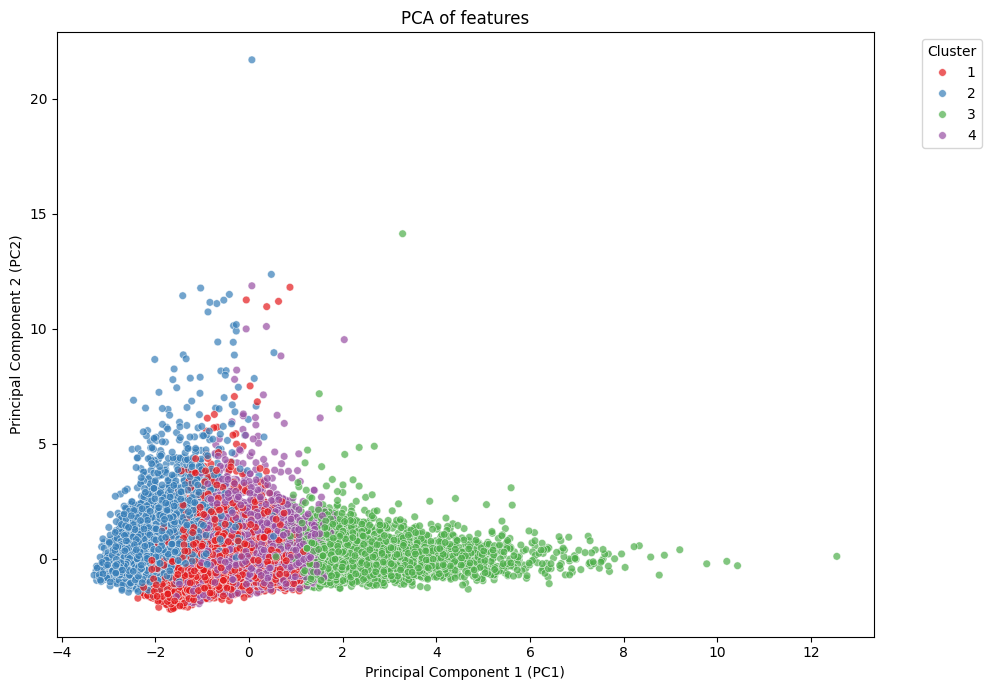

In [45]:
hc_data['PC1'] = data_pca[:, 0]
hc_data['PC2'] = data_pca[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=hc_data,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='Set1',
    alpha=0.7,
    s=30,
)

plt.title('PCA of features')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Variance explained by PC1: 43.51%
Variance explained by PC2: 20.65%
Total cumulative variance retained: 64.16%


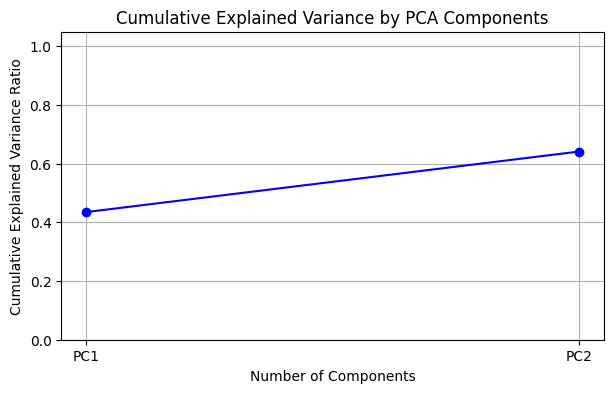

In [46]:
exp_var = pca.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

print(f"Variance explained by PC1: {exp_var[0]*100:.2f}%")
print(f"Variance explained by PC2: {exp_var[1]*100:.2f}%")
print(f"Total cumulative variance retained: {cum_var[1]*100:.2f}%")

plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(exp_var) + 1),
    cum_var,
    marker='o',
    linestyle='-',
    color='b',
)
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.xticks([1, 2], ['PC1', 'PC2'])
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

Seeing as PCA is unsupervised machine learning, the variance is our key take away. The model and reducing the 5 featurs to 2 shows 64% of the variance, which is a strong percentage, however the missing ~35% is still substantial. However, what is key to note is that our 'Champs' cluster is quite visible in this visualisation, which is relfective of its high performance in frequency and CLV.

In [47]:
pca_full = PCA(n_components=None)
pca_full.fit(hc_data[feat_cols])

cum_variance = np.cumsum(pca_full.explained_variance_ratio_)
for i, var in enumerate(cum_variance, start=1):
    print(f"Components 1 to {i}: {var*100:.2f}% of total variance")

Components 1 to 1: 43.51% of total variance
Components 1 to 2: 64.16% of total variance
Components 1 to 3: 83.37% of total variance
Components 1 to 4: 98.55% of total variance
Components 1 to 5: 100.00% of total variance


So while reduction to 2 dimensions at 65% variance is useful, there is a substantial gap between the variance between 2 and 3 components, suggesting it is not the most effective usage.

# Dimension Reduction - t-SNE

As a result of extemely long execution times, even for the 30,000 sample, we have used an even smaller sample of 5,000 to run.

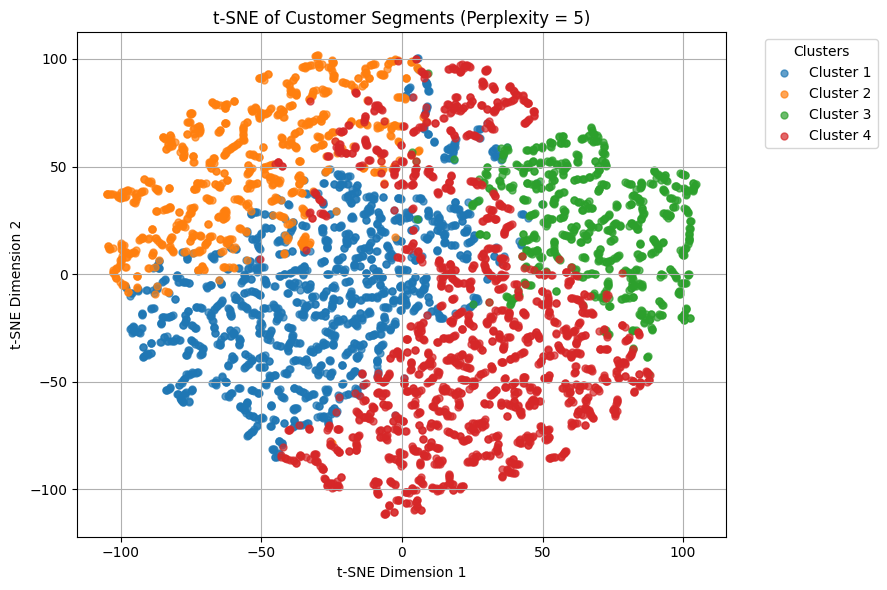

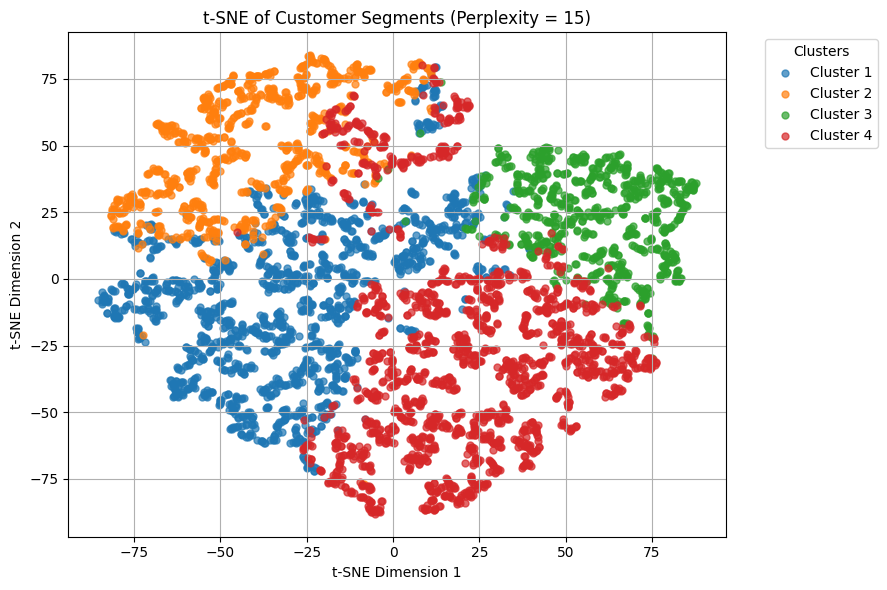

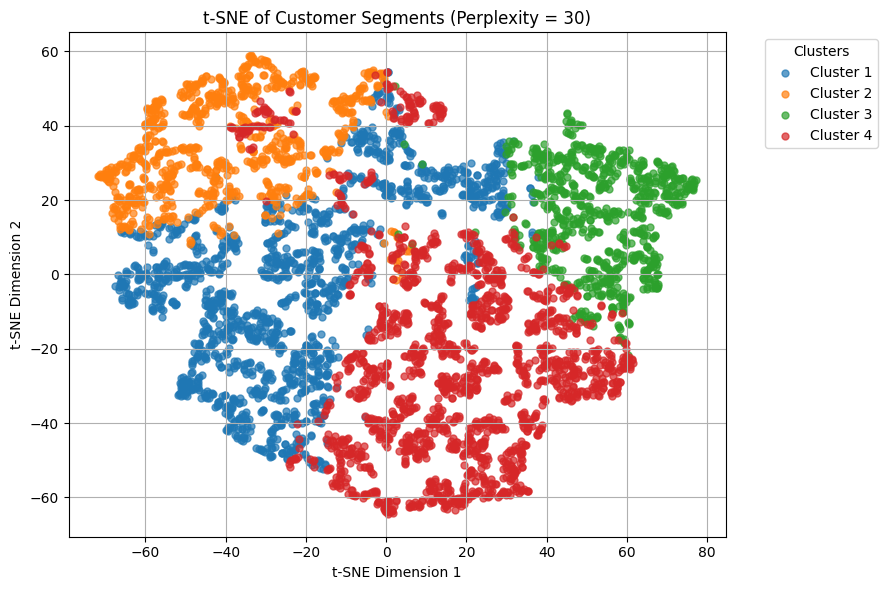

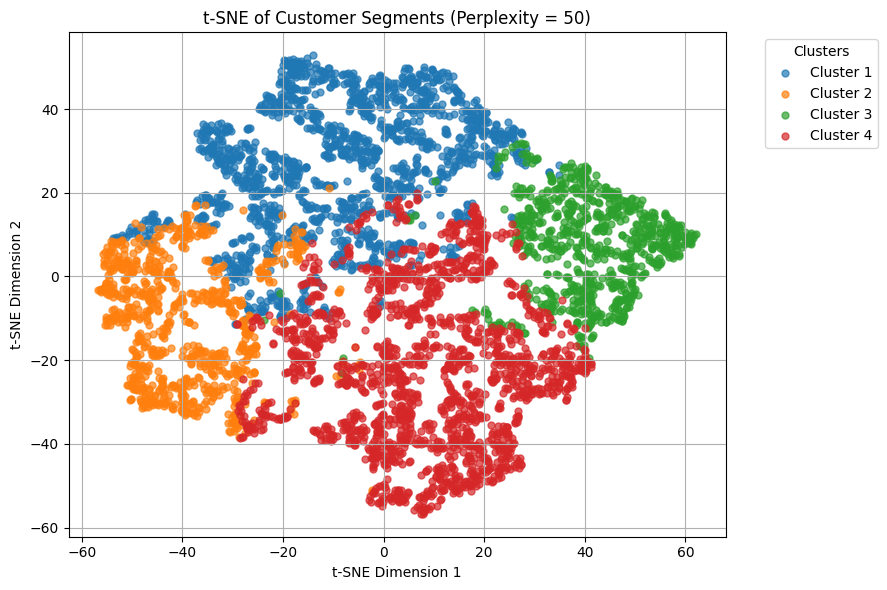

In [48]:
tsne_sample = hc_data.sample(n=5000, random_state=42).reset_index(drop=True)

def plot_embedding(X, title, y_subset):
  plt.figure(figsize=(9, 6))
  for i in range(1, 5):
    idx = y_subset == i
    plt.scatter(
        X[idx, 0], X[idx, 1], label=f'Cluster {i}', alpha=0.7, s=25
    )

  plt.xlabel('t-SNE Dimension 1')
  plt.ylabel('t-SNE Dimension 2')
  plt.legend(title='Clusters', bbox_to_anchor=(1.05, 1), loc='upper left')
  plt.title(title)
  plt.grid(True)
  plt.tight_layout()
  plt.show()

for p in [5, 15, 30, 50]:
  tsne_model = TSNE(n_components=2, perplexity=p, random_state=42)
  tsne_results = tsne_model.fit_transform(tsne_sample[feat_cols])

  plot_embedding(
      tsne_results,
      f't-SNE of Customer Segments (Perplexity = {p})',
      tsne_sample['cluster'].values,
  )

From the multi-perplexity analysis conducted, when the perplexity = 50, we get the clearest definitions of our clusters, with the least overlap. This form of visualisation seems to fit our work better than PCA given the clearly defined clusters we are able to see.

### Reference:
SAS, 2024. CUSTOMERS_CLEAN [Data set]. SAS. Last revised on 15 December 2021. [Accessed 20 February 2024].